In [1]:
import numpy as np
import pandas as pd

In [2]:
import seaborn as sns

In [3]:
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


#### Mostly we use Pivot Tables on the Categorical Data

In [4]:
# Normal Way - Average Bill paid by male and female

In [7]:
df.groupby('sex')['total_bill'].mean()

C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\3379495421.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('sex')['total_bill'].mean()


sex
Male      20.744076
Female    18.056897
Name: total_bill, dtype: float64

In [11]:
# Average bill paid by smoker vs non smoker male and female 

df.groupby(['sex','smoker'])[['total_bill']].mean().unstack()

C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\3322358482.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['sex','smoker'])[['total_bill']].mean().unstack()


total_bill           
smoker        Yes         No
sex                         
Male    22.284500  19.791237
Female  17.977879  18.105185

In [14]:
#Using Pivot Tables 

df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='median')

C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\1675397779.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='median')


smoker,Yes,No
sex,,
Male,20.39,18.24
Female,16.27,16.69


In [26]:
# MultiDimensional Analysis 

df.pivot_table(index=['sex','smoker'],columns=['day','time'],aggfunc={'size':'mean','tip':'median','total_bill':'sum'})

C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\3447440011.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df.pivot_table(index=['sex','smoker'],columns=['day','time'],aggfunc={'size':'mean','tip':'median','total_bill':'sum'})


size                                                tip  \
day                Thur              Fri              Sat       Sun   Thur   
time              Lunch Dinner     Lunch Dinner    Dinner    Dinner  Lunch   
sex    smoker                                                                
Male   Yes     2.300000    NaN  1.666667    2.4  2.629630  2.600000  2.780   
       No      2.500000    NaN       NaN    2.0  2.656250  2.883721  2.405   
Female Yes     2.428571    NaN  2.000000    2.0  2.200000  2.500000  2.500   
       No      2.500000    2.0  3.000000    2.0  2.307692  3.071429  2.000   

                                                total_bill                \
day                    Fri           Sat    Sun       Thur           Fri   
time          Dinner Lunch Dinner Dinner Dinner      Lunch Dinner  Lunch   
sex    smoker                                                              
Male   Yes       NaN  1.92   3.00   3.00    3.5     191.71   0.00  34.16   
       No        NaN   NaN   2.50   2.86    3.0     369.73   0.00   0.00   
Female Yes       NaN  2.50   2.75   2.50    3.5     134.53   0.00  39.78   
       No        3.0  3.00   3.25   2.75    3.5     381.58  18.78  15.98   

                                                   
day                     Sat           Sun          
time           Dinner Lunch  Dinner Lunch  Dinner  
sex    smoker                                      
Male   Yes     129.46   0.0  589.62   0.0  392.12  
       No       34.95   0.0  637.73   0.0  877.34  
Female Yes      48.80   0.0  304.00   0.0   66.16  
       No       22.75   0.0  247.05   0.0  291.54

In [28]:
# Margins 

df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='sum',margins=True)

C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\761643010.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df.pivot_table(index='sex',columns='smoker',values='total_bill',aggfunc='sum',margins=True)


smoker,Yes,No,All
sex,,,
Male,1337.07,1919.75,3256.82
Female,593.27,977.68,1570.95
All,1930.34,2897.43,4827.77


In [29]:
df = pd.read_csv('expense_data.csv')

In [30]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            277 non-null    object 
 1   Account         277 non-null    object 
 2   Category        277 non-null    object 
 3   Subcategory     0 non-null      float64
 4   Note            273 non-null    object 
 5   INR             277 non-null    float64
 6   Income/Expense  277 non-null    object 
 7   Note.1          0 non-null      float64
 8   Amount          277 non-null    float64
 9   Currency        277 non-null    object 
 10  Account.1       277 non-null    float64
dtypes: float64(5), object(6)
memory usage: 23.9+ KB


In [33]:
df['Date'] = pd.to_datetime(df['Date'])

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[ns]
 1   Account         277 non-null    object        
 2   Category        277 non-null    object        
 3   Subcategory     0 non-null      float64       
 4   Note            273 non-null    object        
 5   INR             277 non-null    float64       
 6   Income/Expense  277 non-null    object        
 7   Note.1          0 non-null      float64       
 8   Amount          277 non-null    float64       
 9   Currency        277 non-null    object        
 10  Account.1       277 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 23.9+ KB


In [37]:
df['Month'] = df['Date'].dt.month_name()

In [38]:
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,Month
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,March
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,March
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,March
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,March
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,March


C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\1080109233.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  df.pivot_table(index='Category',columns='Month',values='INR',aggfunc=sum,margins=True,fill_value=0).plot()
C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\1080109233.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  df.pivot_table(index='Category',columns='Month',values='INR',aggfunc=sum,margins=True,fill_value=0).plot()
C:\Users\RonitJadhav\AppData\Local\Temp\ipykernel_28244\1080109233.py:1: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupB

<Axes: xlabel='Category'>

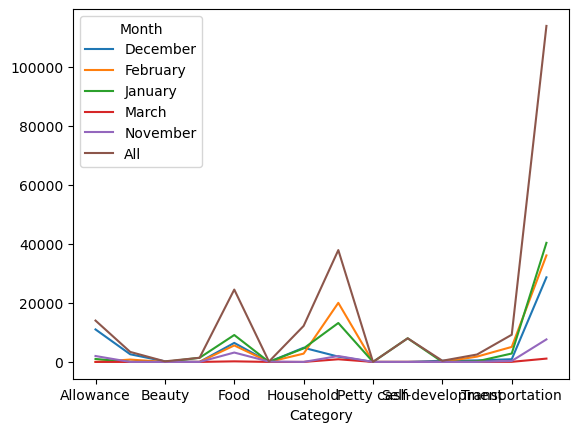

In [44]:
df.pivot_table(index='Category',columns='Month',values='INR',aggfunc=sum,margins=True,fill_value=0).plot()